In [13]:
from PIL import Image

image = Image.open("my_photo.jpg").convert("RGB")
image.save("cover.png")

print("Cover image created successfully!")


Cover image created successfully!


In [16]:
def sequential_embed(image_path, message, output_path):
    img = Image.open(image_path).convert("RGB")
    pixels = list(img.getdata())

    values = [c for pixel in pixels for c in pixel]

    data = message.encode("utf-8")
    payload = len(data).to_bytes(4, "big") + data
    bits = ''.join(f'{byte:08b}' for byte in payload)

    if len(bits) > len(values):
        raise ValueError("Message is too large!")

    for i, bit in enumerate(bits):
        values[i] = (values[i] & 254) | int(bit)

    new_pixels = [
        tuple(values[i:i+3])
        for i in range(0, len(values), 3)
    ]

    img.putdata(new_pixels)
    img.save(output_path)


def sequential_extract(image_path):
    img = Image.open(image_path).convert("RGB")
    pixels = list(img.getdata())

    values = [c for pixel in pixels for c in pixel]

    header_bits = ''.join(str(v & 1) for v in values[:32])
    length = int(header_bits, 2)

    if length > (len(values) - 32) // 8:
        raise ValueError("Invalid message length!")

    message_bits = ''.join(
        str(v & 1)
        for v in values[32:32 + length * 8]
    )

    data = bytes(
        int(message_bits[i:i+8], 2)
        for i in range(0, len(message_bits), 8)
    )

    return data.decode("utf-8")

In [17]:
sequential_embed(
    "cover.png",
    "Hello Nelisa!",
    "sequential.png"
)

message = sequential_extract("sequential.png")
print(message)

C:\Users\hp\AppData\Local\Temp\ipykernel_2744\3634585791.py:3: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(img.getdata())


Hello Nelisa!


C:\Users\hp\AppData\Local\Temp\ipykernel_2744\3634585791.py:28: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(img.getdata())


In [18]:
import random
def random_embed(image_path, message, output_path, seed):
    img = Image.open(image_path).convert("RGB")
    pixels = list(img.getdata())
    values = [c for pixel in pixels for c in pixel]

    data = message.encode("utf-8")
    header = len(data).to_bytes(4, "big")
    header_bits = ''.join(f'{byte:08b}' for byte in header)
    message_bits = ''.join(f'{byte:08b}' for byte in data)

    if 32 + len(message_bits) > len(values):
        raise ValueError("Message is too large!")

    for i, bit in enumerate(header_bits):
        values[i] = (values[i] & 254) | int(bit)

    rng = random.Random(seed)
    positions = rng.sample(
        range(32, len(values)),
        len(message_bits)
    )

    for position, bit in zip(positions, message_bits):
        values[position] = (values[position] & 254) | int(bit)

    img.putdata([
        tuple(values[i:i+3])
        for i in range(0, len(values), 3)
    ])

    img.save(output_path)


def random_extract(image_path, seed):
    img = Image.open(image_path).convert("RGB")
    pixels = list(img.getdata())
    values = [c for pixel in pixels for c in pixel]

    header_bits = ''.join(str(v & 1) for v in values[:32])
    length = int(header_bits, 2)
    total_bits = length * 8

    if total_bits > len(values) - 32:
        raise ValueError("Invalid message length!")

    rng = random.Random(seed)
    positions = rng.sample(
        range(32, len(values)),
        total_bits
    )

    message_bits = ''.join(
        str(values[pos] & 1)
        for pos in positions
    )

    data = bytes(
        int(message_bits[i:i+8], 2)
        for i in range(0, len(message_bits), 8)
    )

    return data.decode("utf-8")

In [19]:
random_embed(
    "cover.png",
    "Hello Nelisa!",
    "random.png",
    seed=12345
)

message = random_extract("random.png", seed=12345)
print(message)

C:\Users\hp\AppData\Local\Temp\ipykernel_2744\1116750057.py:4: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(img.getdata())


Hello Nelisa!


C:\Users\hp\AppData\Local\Temp\ipykernel_2744\1116750057.py:37: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(img.getdata())


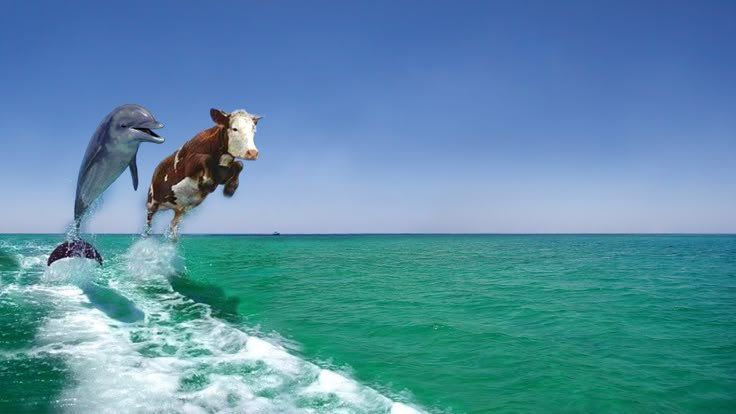

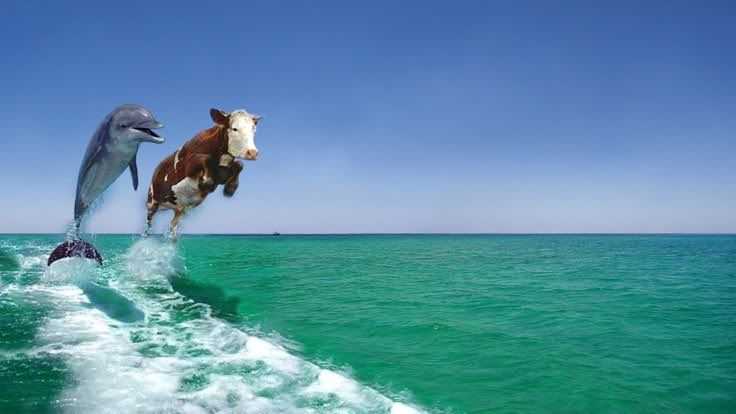

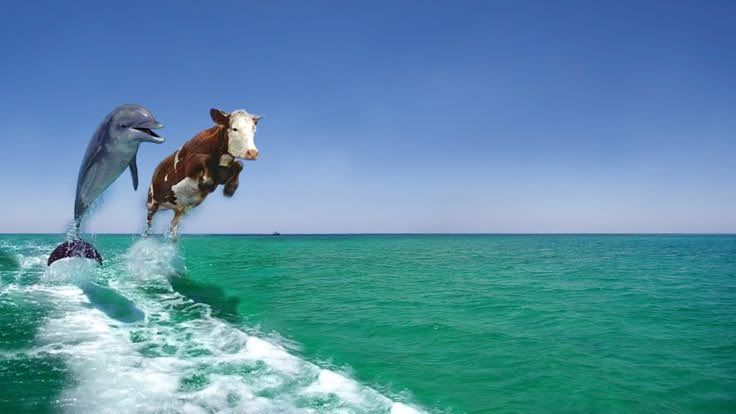

In [20]:
from PIL import Image
from IPython.display import display

display(Image.open("cover.png"))
display(Image.open("sequential.png"))
display(Image.open("random.png"))

In [21]:
original_message = "Hello Nelisa!"

sequential_message = sequential_extract("sequential.png")
random_message = random_extract("random.png", seed=12345)

print("Sequential:", sequential_message)
print("Random:", random_message)

print("Sequential Match:", sequential_message == original_message)
print("Random Match:", random_message == original_message)


Sequential: Hello Nelisa!
Random: Hello Nelisa!
Sequential Match: True
Random Match: True


C:\Users\hp\AppData\Local\Temp\ipykernel_2744\3634585791.py:28: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(img.getdata())
C:\Users\hp\AppData\Local\Temp\ipykernel_2744\1116750057.py:37: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(img.getdata())


Sequential:
Changed Pixels: 40
MSE: 0.00007658
PSNR: 89.29 dB


C:\Users\hp\AppData\Local\Temp\ipykernel_2744\3328368372.py:22: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  for pixel in difference.getdata()


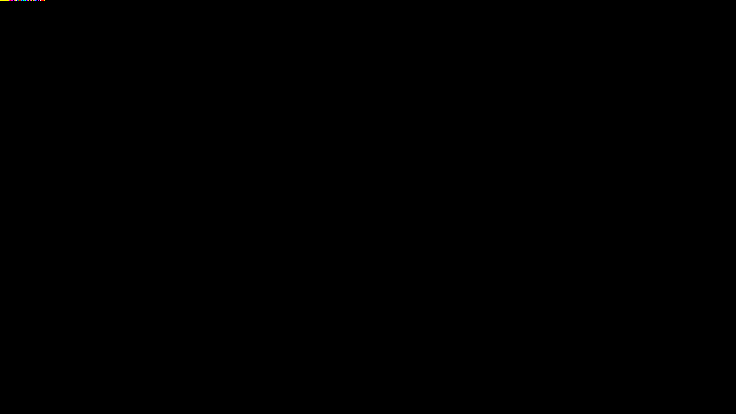

Random:
Changed Pixels: 59
MSE: 0.00007548
PSNR: 89.35 dB


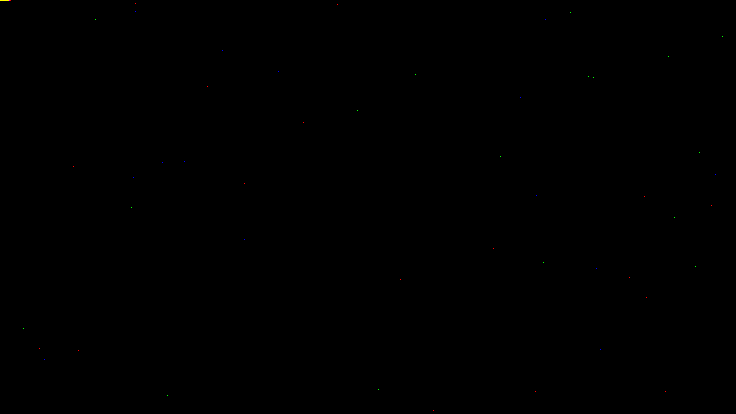

In [22]:
from PIL import Image, ImageChops, ImageStat
from IPython.display import display
import math

cover = Image.open("cover.png").convert("RGB")

for method, filename in [
    ("Sequential", "sequential.png"),
    ("Random", "random.png")
]:
    stego = Image.open(filename).convert("RGB")

    difference = ImageChops.difference(cover, stego)

    rms = ImageStat.Stat(difference).rms
    mse = sum(value ** 2 for value in rms) / 3

    psnr = float("inf") if mse == 0 else 10 * math.log10(255 ** 2 / mse)

    changed_pixels = sum(
        any(channel != 0 for channel in pixel)
        for pixel in difference.getdata()
    )

    print(f"{method}:")
    print(f"Changed Pixels: {changed_pixels}")
    print(f"MSE: {mse:.8f}")
    print(f"PSNR: {psnr:.2f} dB")

    difference_mask = difference.point(
        lambda value: 255 if value > 0 else 0
    )

    display(difference_mask)